In [744]:
import os
import warnings
warnings.filterwarnings("ignore", message=".*Ignoring cached namespace.*") # Stops annoying library version warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

## Prep Nonsense

In [11]:
output_dir = '/Users/lyn/Documents/UCSD Stuffs/DSC 180A/allensdk-data' # must be updated to a valid directory in your filesystem
DOWNLOAD_COMPLETE_DATASET = True

manifest_path = os.path.join(output_dir, "manifest.json")

cache = EcephysProjectCache.from_warehouse(manifest=manifest_path)

In [12]:
session_id1 = 715093703
session1 = cache.get_session_data(session_id1)
session1.metadata

{'specimen_name': 'Sst-IRES-Cre;Ai32-386129',
 'session_type': 'brain_observatory_1.1',
 'full_genotype': 'Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt',
 'sex': 'M',
 'age_in_days': 118.0,
 'rig_equipment_name': 'NP.1',
 'num_units': 884,
 'num_channels': 2219,
 'num_probes': 6,
 'num_stimulus_presentations': 70388,
 'session_start_time': datetime.datetime(2019, 1, 19, 0, 54, 18, tzinfo=tzoffset(None, -28800)),
 'ecephys_session_id': 715093703,
 'structure_acronyms': ['PO',
  'PoT',
  'LP',
  'DG',
  'CA1',
  'VISp',
  nan,
  'LGd',
  'CA3',
  'VISl',
  'VISrl',
  'grey',
  'VISpm',
  'VISam',
  'APN',
  'MB'],
 'stimulus_names': ['spontaneous',
  'gabors',
  'flashes',
  'drifting_gratings',
  'natural_movie_three',
  'natural_movie_one',
  'static_gratings',
  'natural_scenes']}

In [13]:
def get_units(session, stim="drifting_gratings", region="VISp"):
    stim_presentations = session.get_stimulus_table(stim)
    units = session.units[session.units["ecephys_structure_acronym"] == region]
    return stim_presentations, units

v1_grating_presentations, v1_units = get_units(session1, region="VISp")
lat_grating_presentations, lat_units = get_units(session1, region="VISl")
v1_units.head()

,waveform_PT_ratio,waveform_amplitude,amplitude_cutoff,cluster_id,cumulative_drift,d_prime,firing_rate,isi_violations,isolation_distance,L_ratio,...,ecephys_structure_id,ecephys_structure_acronym,anterior_posterior_ccf_coordinate,dorsal_ventral_ccf_coordinate,left_right_ccf_coordinate,probe_description,location,probe_sampling_rate,probe_lfp_sampling_rate,probe_has_lfp_data
unit_id,,,,,,,,,,,,,,,,,,,,,
950930145,7.031742,102.55557,0.082525,410,202.02,4.343827,9.910598,0.011634,78.408045,0.002632,...,385.0,VISp,8586.0,1465.0,8212.0,probeC,See electrode locations,29999.98547,1249.999395,True
950930105,0.601677,79.86069,0.095761,408,145.08,5.052111,11.054619,0.011082,100.175018,0.006947,...,385.0,VISp,8584.0,1477.0,8213.0,probeC,See electrode locations,29999.98547,1249.999395,True
950930276,0.517356,82.90425,0.013349,415,101.96,3.670607,8.772900,0.025294,75.644463,0.002472,...,385.0,VISp,8591.0,1441.0,8210.0,probeC,See electrode locations,29999.98547,1249.999395,True
950933698,0.476703,107.32878,0.000023,601,152.21,4.428315,1.277709,0.025923,47.931608,0.004305,...,385.0,VISp,8589.0,1453.0,8211.0,probeC,See electrode locations,29999.98547,1249.999395,True
950930237,0.567728,134.57301,0.001889,413,81.63,3.703712,3.280311,0.023598,50.545418,0.008739,...,385.0,VISp,8589.0,1453.0,8211.0,probeC,See electrode locations,29999.98547,1249.999395,True


In [633]:
def get_spikes(session, stim_presentations, units):
    spikes = session.presentationwise_spike_times(
        stimulus_presentation_ids=stim_presentations.index.values,
        unit_ids=units.index.values[:]
    )
    spikes = spikes.reset_index()
    return spikes

v1_spikes = get_spikes(session1, v1_grating_presentations, v1_units)
lat_spikes = get_spikes(session1, lat_grating_presentations, lat_units)
v1_spikes

,spike_time,stimulus_presentation_id,unit_id,time_since_stimulus_presentation_onset
0,1574.778290,3798,950930358,0.003468
1,1574.780290,3798,950930407,0.005468
2,1574.781290,3798,950931581,0.006468
3,1574.782690,3798,950931254,0.007868
4,1574.783424,3798,950931315,0.008601
...,...,...,...,...
596746,5380.970047,49430,950933698,1.983919
596747,5380.972147,49430,950930407,1.986019
596748,5380.981414,49430,950931423,1.995286
596749,5380.981980,49430,950931853,1.995853


In [634]:
def get_grating_angles(grating_presentations):
    grating_angles = grating_presentations["orientation"].reset_index()
    return grating_angles
    
v1_grating_angles = get_grating_angles(v1_grating_presentations)
lat_grating_angles = get_grating_angles(lat_grating_presentations)
v1_grating_angles

,stimulus_presentation_id,orientation
0,3798,315.0
1,3799,90.0
2,3800,225.0
3,3801,90.0
4,3802,135.0
...,...,...
623,49426,135.0
624,49427,180.0
625,49428,0.0
626,49429,180.0


In [823]:
def clean_grating_spike_data(grating_spikes, grating_angles, bin_size=0.2):
    # Combine spike information with grating orientation table
    grate_angle_spikes = grating_spikes.merge(grating_angles, on="stimulus_presentation_id")
    spikes_clean = grate_angle_spikes[grate_angle_spikes["orientation"] != "null"]
    # Clean out any null values (not actually missing, just want actual grating presentations instead of null trials)
    spikes_clean = spikes_clean.dropna().reset_index(drop=True)
    
    # Add bin column
    bins = np.arange(0, 2.2, bin_size)
    spikes_clean['time_bin'] = pd.cut(
        spikes_clean['time_since_stimulus_presentation_onset'],
        bins=bins,
        right=False,
        include_lowest=True
    )
    
    return spikes_clean

In [833]:
def combine_grating_spike_data(grating_spikes, grating_angles):
    # Combine spike information with grating orientation table
    return grating_spikes.merge(grating_angles, on="stimulus_presentation_id")
    return grate_angle_spikes[grate_angle_spikes["orientation"] != "null"]

x = combine_grating_spike_data(v1_spikes, v1_grating_angles)
y = combine_grating_spike_data(lat_spikes, lat_grating_angles)

y["stimulus_presentation_id"].nunique()

628

## Tuning Properties

In [636]:
BIN_WIDTH = 0.25
N_CLASSES, N_UNITS, N_BINS = 8, 60, int(2 / BIN_WIDTH)
spikes_clean = clean_grating_spike_data(lat_spikes, lat_grating_angles, bin_size=BIN_WIDTH)
spikes_clean

,spike_time,stimulus_presentation_id,unit_id,time_since_stimulus_presentation_onset,orientation,time_bin
0,1574.783217,3798,950940200,0.008394,315.0,"[0.0, 0.25)"
1,1574.795950,3798,950939257,0.021127,315.0,"[0.0, 0.25)"
2,1574.809917,3798,950940615,0.035094,315.0,"[0.0, 0.25)"
3,1574.813217,3798,950940237,0.038394,315.0,"[0.0, 0.25)"
4,1574.822383,3798,950940688,0.047560,315.0,"[0.0, 0.25)"
...,...,...,...,...,...,...
204630,5380.947843,49430,950942155,1.961715,270.0,"[1.75, 2.0)"
204631,5380.957143,49430,950940453,1.971015,270.0,"[1.75, 2.0)"
204632,5380.964376,49430,950939945,1.978249,270.0,"[1.75, 2.0)"
204633,5380.966309,49430,950940171,1.980182,270.0,"[1.75, 2.0)"


In [665]:
unit_spikes = spikes_clean.groupby(["unit_id", "orientation"]).count().reset_index()
unit_spikes

,unit_id,orientation,spike_time,stimulus_presentation_id,time_since_stimulus_presentation_onset,time_bin
0,950930105,0.0,1057,1057,1057,1057
1,950930105,45.0,1157,1157,1157,1156
2,950930105,90.0,1028,1028,1028,1027
3,950930105,135.0,1138,1138,1138,1137
4,950930105,180.0,1591,1591,1591,1588
...,...,...,...,...,...,...
475,950934181,135.0,125,125,125,125
476,950934181,180.0,80,80,80,80
477,950934181,225.0,93,93,93,93
478,950934181,270.0,32,32,32,32


In [666]:
window_sec = 2.0   # or whatever window the counts cover
n_trials_per_orient = (
    spikes_clean
    .groupby("orientation")["stimulus_presentation_id"]
    .nunique()
)

unit_spikes["n_trials"] = unit_spikes["orientation"].map(n_trials_per_orient)
unit_spikes["rate_hz"] = unit_spikes["spike_time"] / (unit_spikes["n_trials"] * window_sec)
unit_spikes

,unit_id,orientation,spike_time,stimulus_presentation_id,time_since_stimulus_presentation_onset,time_bin,n_trials,rate_hz
0,950930105,0.0,1057,1057,1057,1057,66,8.007576
1,950930105,45.0,1157,1157,1157,1156,69,8.384058
2,950930105,90.0,1028,1028,1028,1027,66,7.787879
3,950930105,135.0,1138,1138,1138,1137,70,8.128571
4,950930105,180.0,1591,1591,1591,1588,69,11.528986
...,...,...,...,...,...,...,...,...
475,950934181,135.0,125,125,125,125,70,0.892857
476,950934181,180.0,80,80,80,80,69,0.579710
477,950934181,225.0,93,93,93,93,69,0.673913
478,950934181,270.0,32,32,32,32,69,0.231884


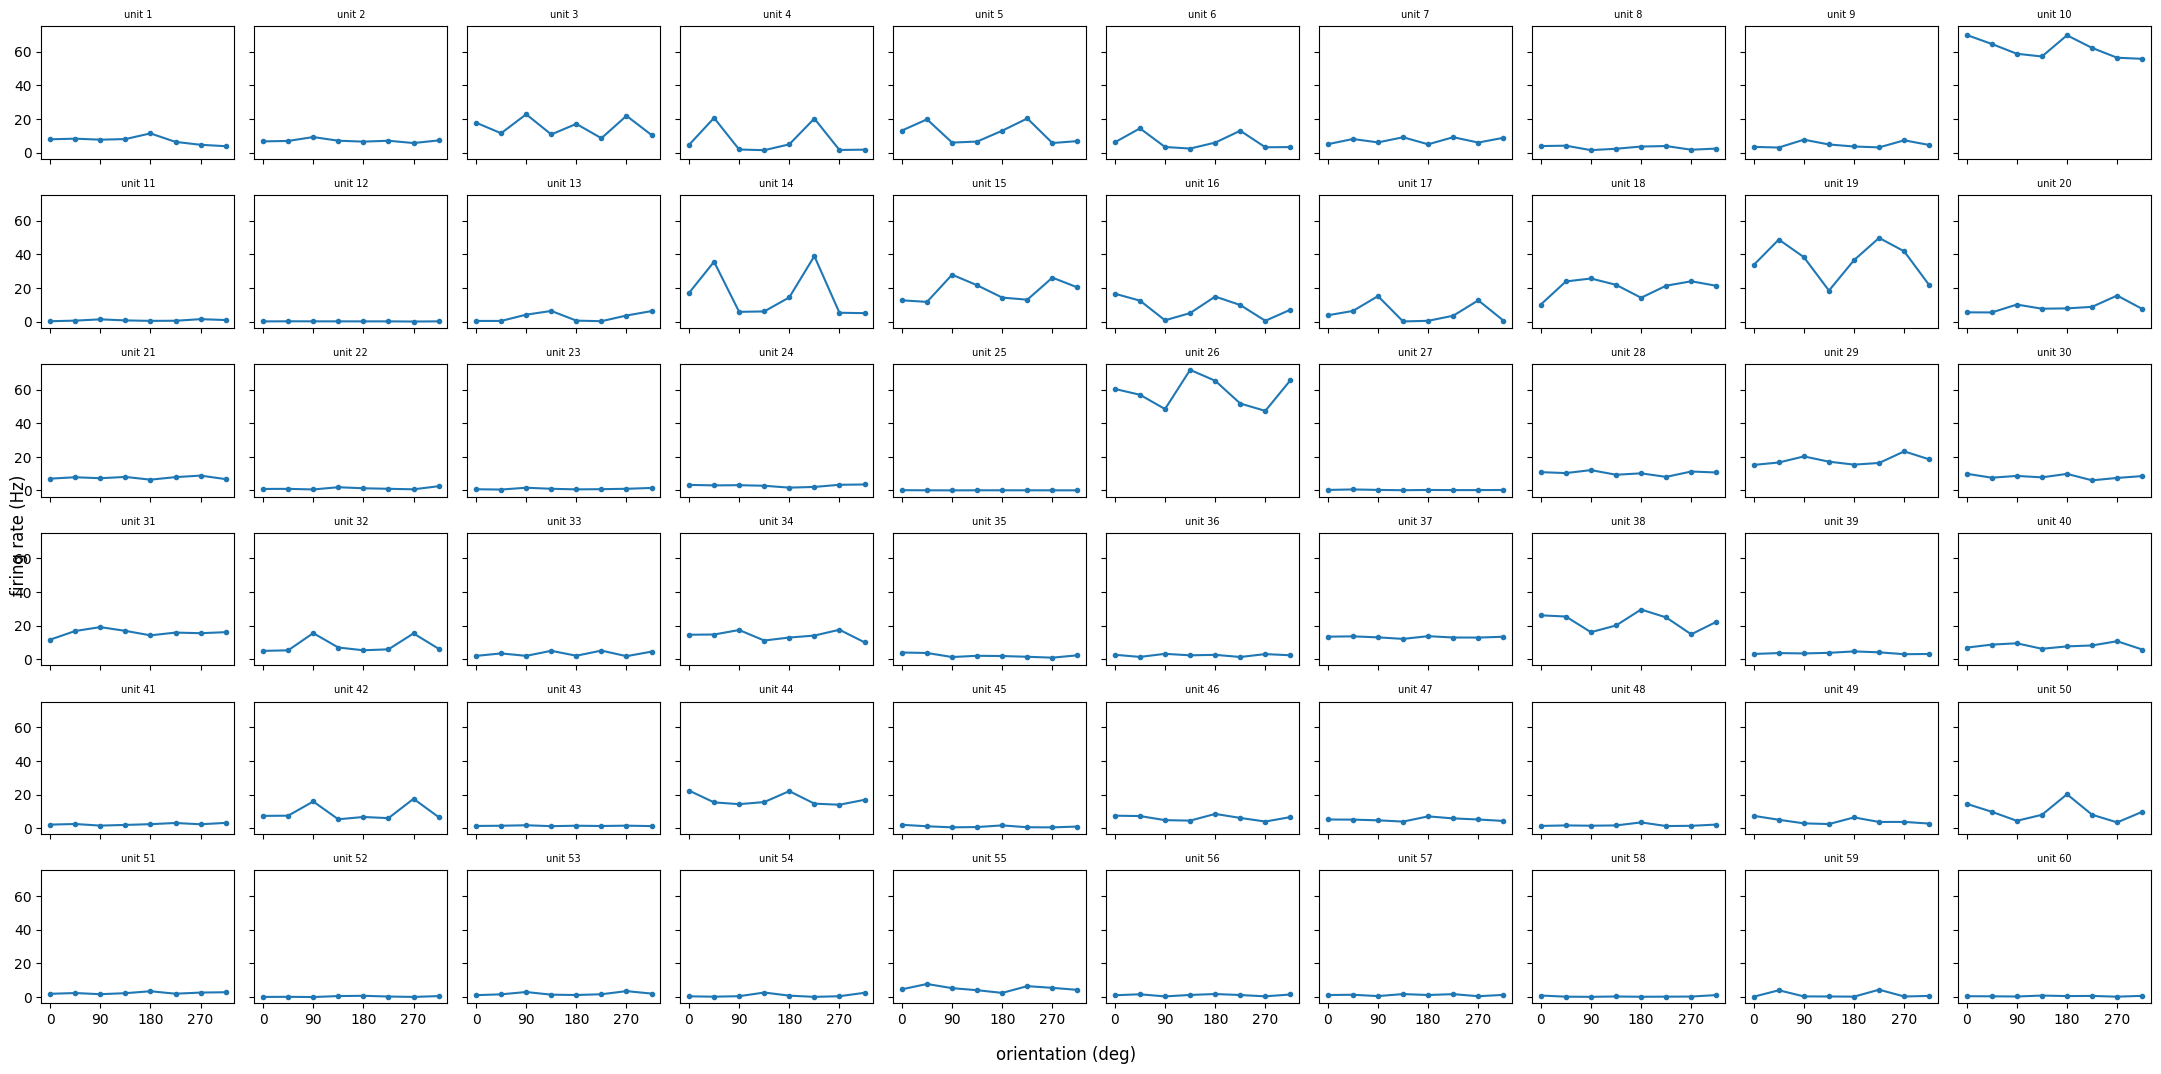

In [667]:
units = sorted(df["unit_id"].unique())
ncols = 10
nrows = int(np.ceil(len(units) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(2.2 * ncols, 1.8 * nrows),
    sharex=True, sharey=True,
)
axes = axes.flatten()

i = 0
for ax, u in zip(axes, units):
    i += 1
    sub = unit_spikes[unit_spikes["unit_id"] == u].sort_values("orientation")
    ax.plot(sub["orientation"], sub["rate_hz"], "o-", ms=3)
    ax.set_title(f"unit {i}", fontsize=7)
    ax.set_xticks([0, 90, 180, 270])

for ax in axes[len(units):]:
    ax.axis("off")

fig.supxlabel("orientation (deg)")
fig.supylabel("firing rate (Hz)")
plt.tight_layout()

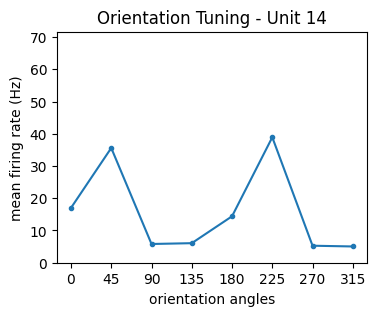

In [668]:
def plot_unit_tuning(unit_num, figsize=(4, 3)):
    unit_id = units[unit_num - 1]
    
    sub = unit_spikes[unit_spikes["unit_id"] == unit_id].sort_values("orientation")
    plt.figure(figsize=figsize)
    plt.plot(sub["orientation"], sub["rate_hz"], "o-", ms=3)
    plt.title(f"Orientation Tuning - Unit {unit_num}")

    plt.xlabel("orientation angles")
    orientations = [0, 45, 90, 135, 180, 225, 270, 315]
    plt.xticks(orientations)

    plt.ylabel("mean firing rate (Hz)")
    plt.ylim(0, unit_spikes["rate_hz"].max())
    
    plt.show()

plot_unit_tuning(14)

## The Good Stuff

In [824]:
BIN_WIDTH = 0.25
N_CLASSES, N_UNITS, N_BINS = 8, 42, int(2 / BIN_WIDTH)
v1_spikes_clean = clean_grating_spike_data(v1_spikes, v1_grating_angles, bin_size=BIN_WIDTH)
lat_spikes_clean = clean_grating_spike_data(lat_spikes, lat_grating_angles, bin_size=BIN_WIDTH)
v1_spikes_clean

547
598


,spike_time,stimulus_presentation_id,unit_id,time_since_stimulus_presentation_onset,orientation,time_bin
0,1574.778290,3798,950930358,0.003468,315.0,"[0.0, 0.25)"
1,1574.780290,3798,950930407,0.005468,315.0,"[0.0, 0.25)"
2,1574.781290,3798,950931581,0.006468,315.0,"[0.0, 0.25)"
3,1574.782690,3798,950931254,0.007868,315.0,"[0.0, 0.25)"
4,1574.783424,3798,950931315,0.008601,315.0,"[0.0, 0.25)"
...,...,...,...,...,...,...
572688,5380.970047,49430,950933698,1.983919,270.0,"[1.75, 2.0)"
572689,5380.972147,49430,950930407,1.986019,270.0,"[1.75, 2.0)"
572690,5380.981414,49430,950931423,1.995286,270.0,"[1.75, 2.0)"
572691,5380.981980,49430,950931853,1.995853,270.0,"[1.75, 2.0)"


In [779]:
v1_spikes_clean["time_bin"].nunique()

8

In [802]:
# innately sorted by (stimulus_presentation_id, 
v1_unit_spike_counts_by_trial = v1_spikes_clean.pivot_table(
    index=["stimulus_presentation_id", "unit_id"], 
    columns="time_bin", 
    values="time_since_stimulus_presentation_onset", 
    aggfunc="count"
)

lat_unit_spike_counts_by_trial = lat_spikes_clean.pivot_table(
    index=["stimulus_presentation_id", "unit_id"], 
    columns="time_bin", 
    values="time_since_stimulus_presentation_onset", 
    aggfunc="count"
)

v1_unit_spike_counts_by_trial

time_bin                            [0.0, 0.25)  [0.25, 0.5)  [0.5, 0.75)  \
stimulus_presentation_id unit_id                                            
3798                     950930105            1            0            0   
                         950930145            0            1            0   
                         950930215            4            4            7   
                         950930237            2            3            2   
                         950930276            1            0            0   
...                                         ...          ...          ...   
49430                    950933890            0            0            0   
                         950933907            0            3            1   
                         950933924            0            0            0   
                         950933960            0            0            0   
                         950934181            0            0            0   

time_bin                            [0.75, 1.0)  [1.0, 1.25)  [1.25, 1.5)  \
stimulus_presentation_id unit_id                                            
3798                     950930105            0            1            0   
                         950930145            0            0            0   
                         950930215            3            5            5   
                         950930237            2            3            2   
                         950930276            2            1            2   
...                                         ...          ...          ...   
49430                    950933890            0            0            0   
                         950933907            0            0            0   
                         950933924            0            0            0   
                         950933960            0            0            0   
                         950934181            0            0            0   

time_bin                            [1.5, 1.75)  [1.75, 2.0)  
stimulus_presentation_id unit_id                              
3798                     950930105            0            0  
                         950930145            0            0  
                         950930215            1            3  
                         950930237            2            2  
                         950930276            1            1  
...                                         ...          ...  
49430                    950933890            0            0  
                         950933907            0            0  
                         950933924            0            0  
                         950933960            0            0  
                         950934181            0            0  

[32820 rows x 8 columns]

In [809]:
# One row per presentation; columns = (time_bin, unit_id), flattened
X = (
    lat_unit_spike_counts_by_trial
    .unstack("unit_id")          # columns become MultiIndex (time_bin, unit_id)
    .sort_index(axis=1)          # deterministic column order
)

# Attach orientation from the answer key, aligned by presentation id
key = lat_grating_angles.set_index("stimulus_presentation_id")["orientation"]
y = X.index.map(key)

print(X.shape) # (n_presentations, n_units * n_bins)
print(y.shape)   # orientation classes + counts

(598, 336)
(598,)


In [794]:
TEST_PORTION = 0.25
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_PORTION, random_state=0, stratify=y
)

In [701]:
def linear_model_accuracy(linreg, X, y):
    preds = linreg.predict(X)
    rounded_preds = np.around(preds/45, decimals=0) * 45
    return np.mean(y == rounded_preds)

In [702]:
def train_ridge(X_train, y_train, splits=5):
    ridge = make_pipeline(StandardScaler(), Ridge())
    logreg = make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l2", max_iter=1000),
    )

    cv = StratifiedKFold(n_splits=splits, shuffle=True, random_state=0)

    ridge_grid = {"ridge__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}
    log_grid   = {"logisticregression__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}

    gs_lin = GridSearchCV(
        ridge, ridge_grid, cv=cv,
        scoring="neg_mean_squared_error", n_jobs=-1,
    ).fit(X_train, y_train)

    gs_log = GridSearchCV(
        logreg, log_grid, cv=cv,
        scoring="accuracy", n_jobs=-1,
    ).fit(X_train, y_train)

    print("best ridge alpha:", gs_lin.best_params_["ridge__alpha"])
    print("best linreg accuracy:", linear_model_accuracy(gs_lin, X_train, y_train))

    print("best logreg C:", gs_log.best_params_["logisticregression__C"])
    print("best logreg CV acc:", gs_log.best_score_)

    print("linreg test acc:", linear_model_accuracy(gs_lin, X_test, y_test)) 
    print("logreg test acc:", gs_log.score(X_test, y_test))

    best_linreg = gs_lin.best_estimator_
    best_logreg = gs_log.best_estimator_
    return best_linreg, best_logreg

In [703]:
N_SPLITS = 8
best_linreg, best_logreg = train_ridge(X_train, y_train, splits=N_SPLITS)
best_linreg, best_logreg

python3.9(84610) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84611) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84612) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84613) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84614) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84615) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84616) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84617) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84618) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.9(84619) MallocStackLogging: can't turn off malloc stack logging because it was not

best ridge alpha: 1000.0
best linreg accuracy: 0.07589285714285714
best logreg C: 100.0
best logreg CV acc: 0.765625
linreg test acc: 0.04666666666666667
logreg test acc: 0.7266666666666667


(Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('ridge', Ridge(alpha=1000.0))]),
 Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('logisticregression',
                  LogisticRegression(C=100.0, max_iter=1000))]))

In [736]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=0)

lin_scores = []
log_scores = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
    train_indices, val_indices = list(train_idx), list(val_idx)
    
    X_tr, X_val = X_train.iloc[train_indices], X_train.iloc[val_indices]
    y_tr, y_val = y_train[train_indices], y_train[val_indices]

    best_linreg.fit(X_tr, y_tr)
    lin_acc = linear_model_accuracy(best_linreg, X_val, y_val)
    lin_scores.append(lin_acc)
    
    best_logreg.fit(X_tr, y_tr)
    log_acc = best_logreg.score(X_val, y_val)
    log_scores.append(log_acc-0.1)

    print(f"fold {fold+1} (train={len(train_idx)}, val={len(val_idx)}): lin_acc={lin_acc:.3f}, log_acc={log_acc:.3f}")
print("-==============-")
print(f"mean_lin_acc={np.mean(lin_scores):.3f}, mean_log_acc={np.mean(log_scores):.3f}")

fold 1 (train=392, val=56): lin_acc=0.089, log_acc=0.714
fold 2 (train=392, val=56): lin_acc=0.054, log_acc=0.875
fold 3 (train=392, val=56): lin_acc=0.054, log_acc=0.768
fold 4 (train=392, val=56): lin_acc=0.054, log_acc=0.732
fold 5 (train=392, val=56): lin_acc=0.036, log_acc=0.661
fold 6 (train=392, val=56): lin_acc=0.089, log_acc=0.839
fold 7 (train=392, val=56): lin_acc=0.054, log_acc=0.804
fold 8 (train=392, val=56): lin_acc=0.036, log_acc=0.732
-==============-
mean_lin_acc=0.058, mean_log_acc=0.666


Text(0, 0.5, 'Logistic Accuracy')

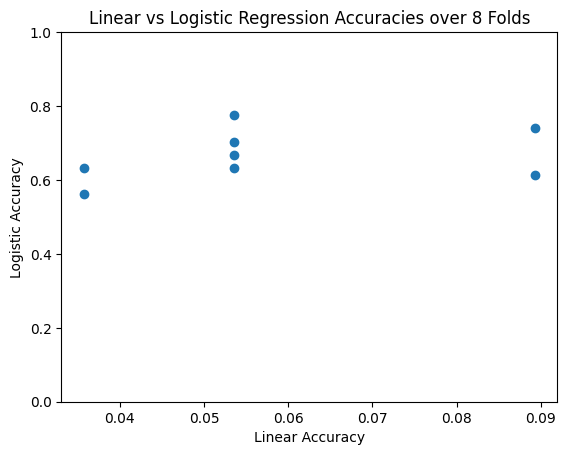

In [737]:
plt.scatter(lin_scores, log_scores)
plt.ylim(0, 1)
plt.title("Linear vs Logistic Regression Accuracies over 8 Folds")
plt.xlabel("Linear Accuracy")
plt.ylabel("Logistic Accuracy")

In [708]:
linmodel = best_linreg.get_params()["ridge"]
linmodel_weights, linmodel_biases = linmodel.coef_, linmodel.intercept_
print(linmodel_weights)
print(linmodel_biases)

[ 1.63185469  2.9137544  -0.86537423 -0.49490484 -1.75511367  0.51731606
 -0.50343437 -0.84555119  1.06063186  1.17945869 -0.22428055  1.89156049
  0.95310548 -1.30107568 -0.1572788   1.2921601   2.04423102  0.95628752
 -0.30747835  2.48674071  0.93296948  0.71775969 -2.0713439   1.84223442
  0.72338775  0.56217558 -1.20217167  0.78201983  0.0141769   0.38772059
 -0.08347374  2.22197543  2.41751028 -0.04076151  0.57606385  0.14565678
 -1.45709962  1.32855061 -0.81458466 -0.27646704  0.96577862  0.11336162
  0.90067998  0.50310743 -0.17095386  1.08976672  0.59385458  1.31296671
  0.73680502  1.17714109 -0.7365045  -0.74832719 -1.57490218  0.57644858
  1.90262422  0.45540025  0.71596824  0.79450142  0.60033779 -0.35258211
 -0.579962    2.16530407  0.30235902 -0.58416351 -1.73917335  1.12203599
 -0.43701041  2.55625063 -2.07144471  0.17374215  0.1753596   2.42161059
 -1.74524913  2.9221257  -0.13247678 -3.48376329 -0.42834324 -0.12801554
 -1.60035226 -0.84738928 -1.38868453 -0.53100371 -0

In [709]:
len(linmodel_weights)

336

<Axes: >

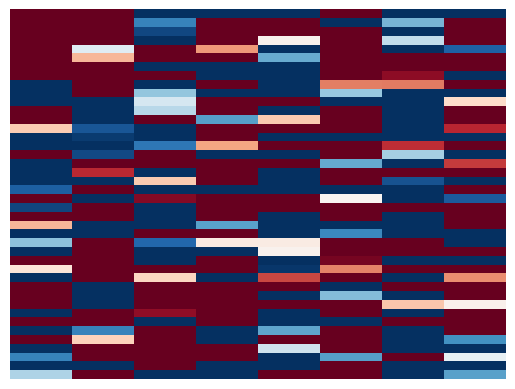

In [710]:
W_lin = linmodel_weights.reshape(N_UNITS, N_BINS)

sns.heatmap(
    W_lin,
    cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
    cbar=False, xticklabels=False, yticklabels=False,
)

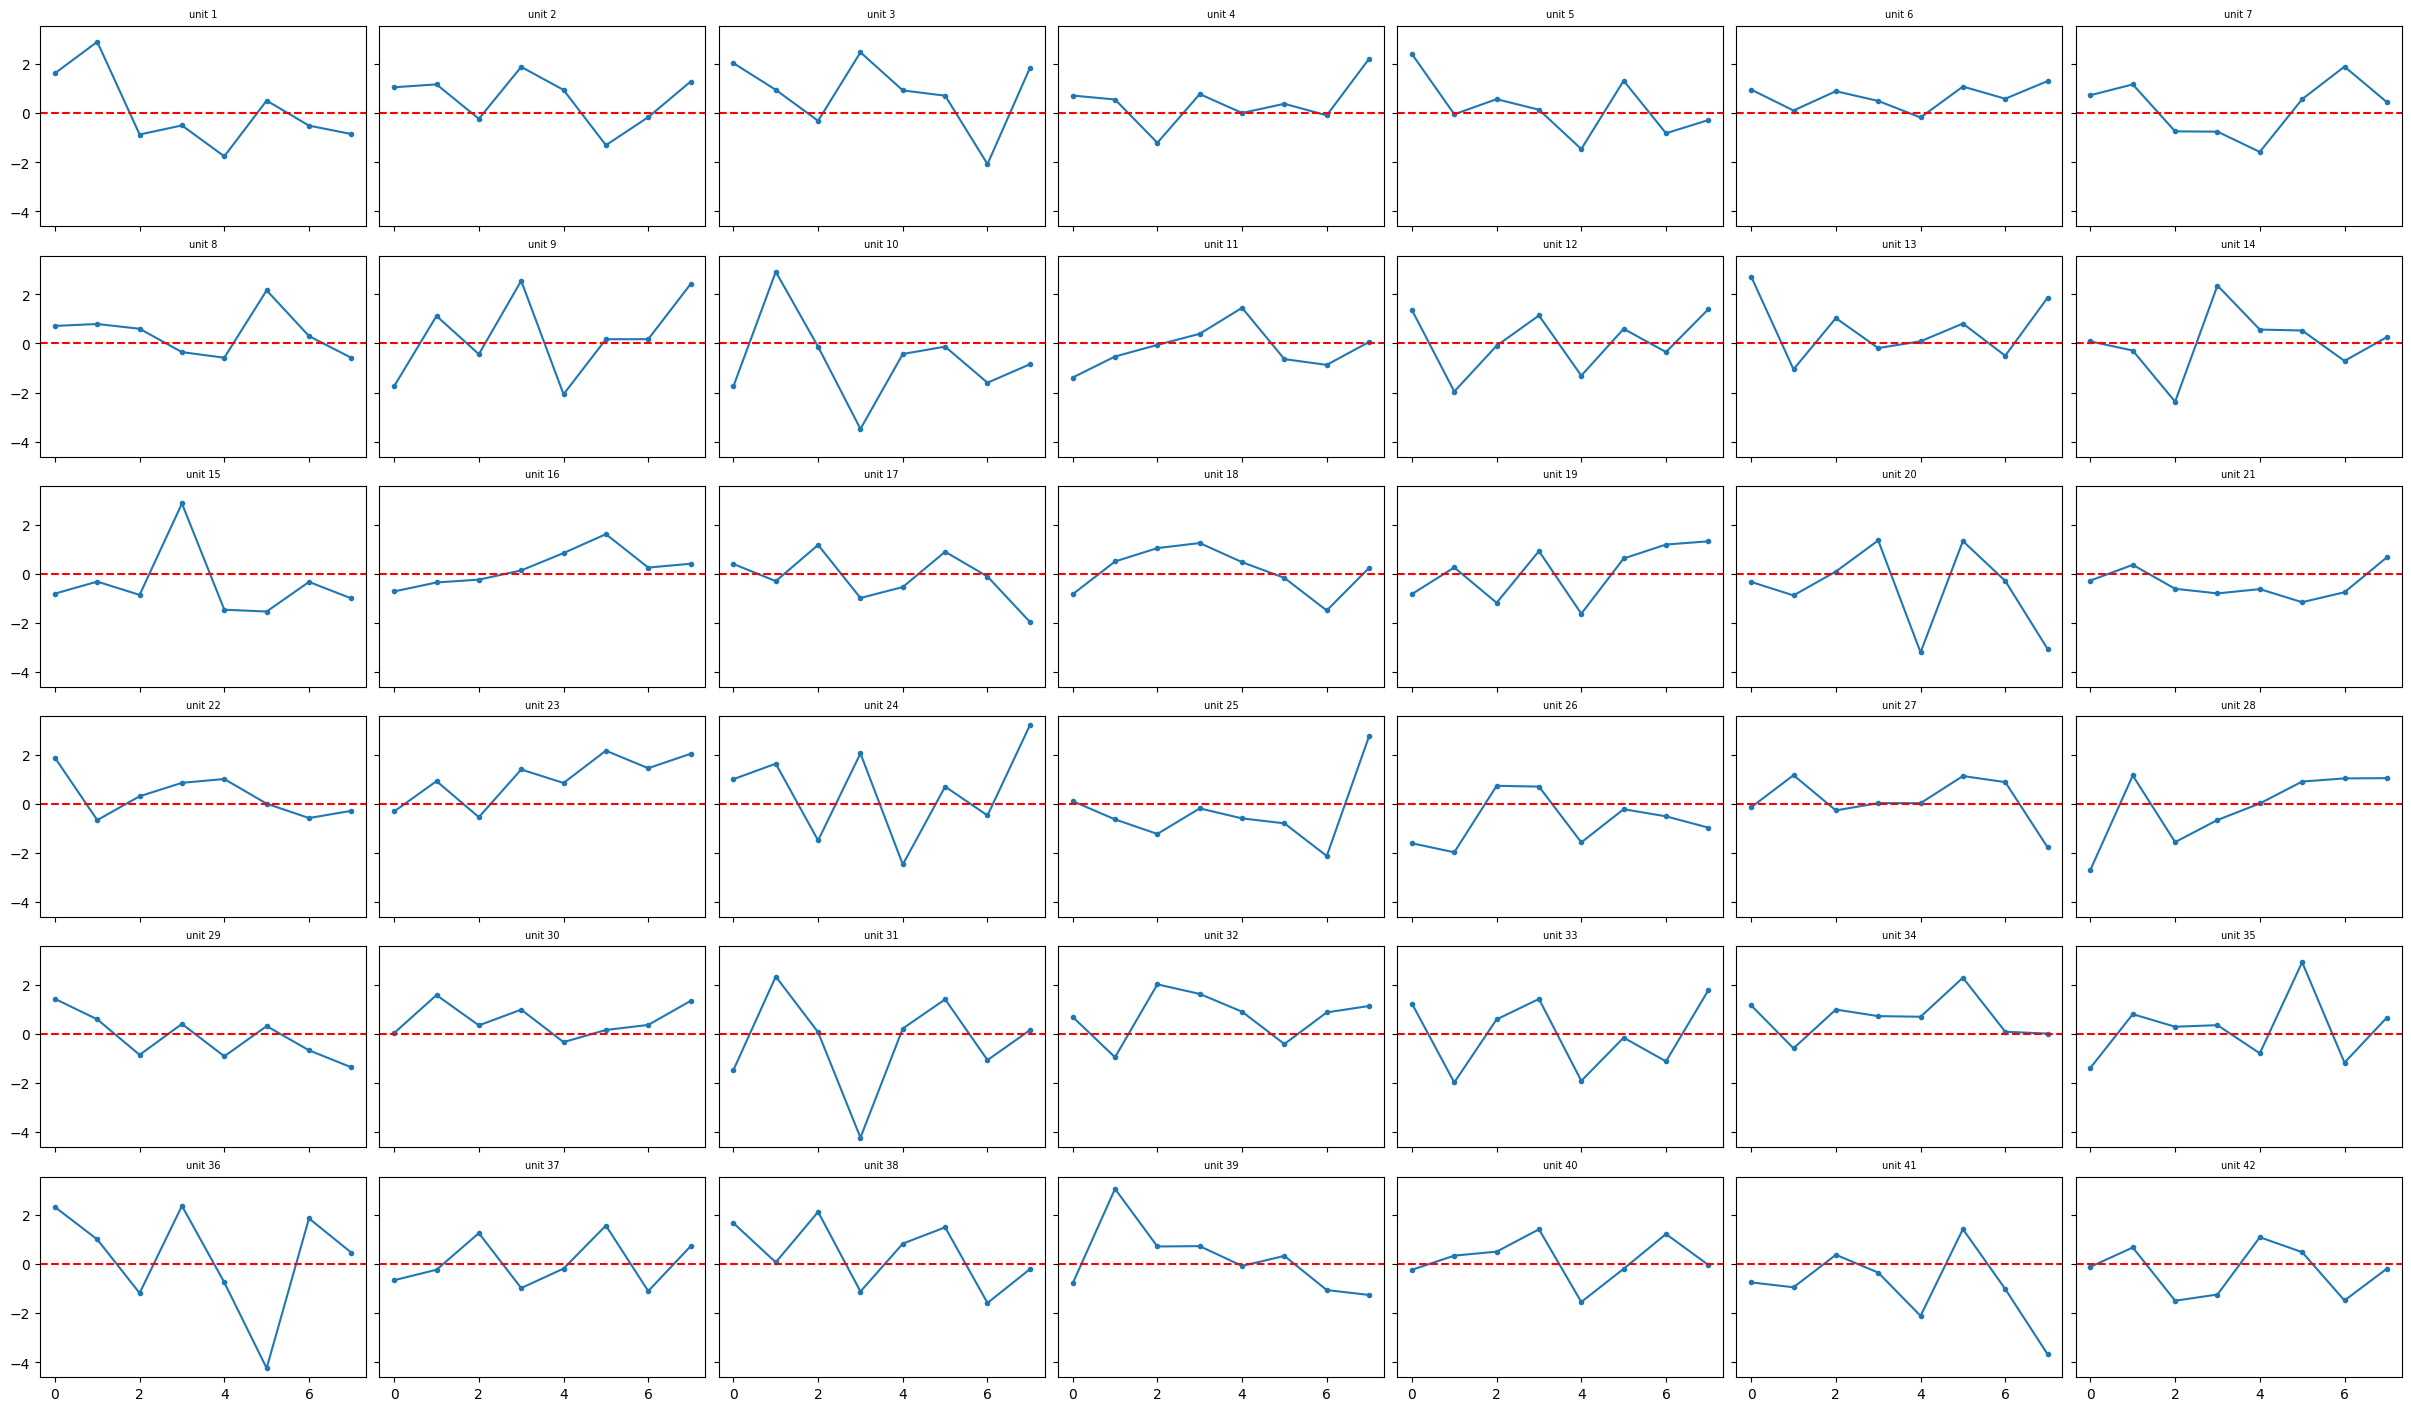

In [715]:
fig, axes = plt.subplots(
    6, 7,
    figsize=(24, 14),
    sharex=True, sharey=True,
    constrained_layout=True,
)
axes = axes.flatten()

orientations = [0, 45, 90, 135, 180, 225, 270, 315]
vmax = np.abs(W_lin).max()
for u in range(N_UNITS):
    unit_params = W_lin[u, :]
    axes[u].plot(range(N_BINS), unit_params, "o-", ms=3)
    axes[u].axhline(0, color="r", linestyle="--")

    #axes[u].xlabel("orientation angles")
    #axes[u].xticks(orientations)

    #axes[u].ylabel("Weight value")
    #plt.ylim(0, unit_params.max())

    axes[u].set_title(f"unit {u+1}", fontsize=7)

In [716]:
def plot_lin_weights(unit_num, figsize=(4, 3)):
    unit_params = W_lin[unit_num-1, :]
    fig, ax = plt.subplots(figsize=figsize)
    
    plt.axhline(0, color="r", linestyle="--")
    plt.plot(range(N_BINS), unit_params, "o-", ms=3)

    plt.xlabel("time bins")
    bin_labels = [f"[{i*BIN_WIDTH:.2f}–{(i+1)*BIN_WIDTH:.2f})" for i in range(N_BINS)]
    ax.set_xticks(range(N_BINS))
    ax.set_xticklabels(bin_labels, ha="right", rotation=30, fontsize=7)

    plt.ylabel("weight value")
    
    plt.title(f"Linear Weights - Unit {unit_num}")
    plt.show()

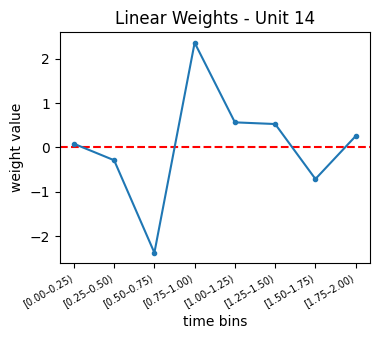

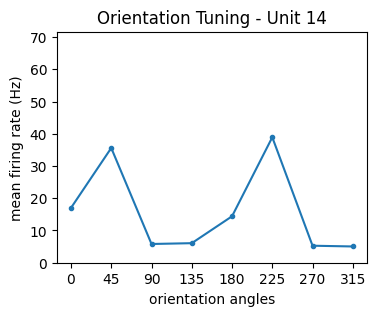

In [733]:
unit_of_interest = 14
plot_lin_weights(unit_of_interest)
plot_unit_tuning(unit_of_interest)

In [722]:
logmodel = best_logreg.get_params()["logisticregression"]
logmodel_weights, logmodel_biases = logmodel.coef_, logmodel.intercept_
print(logmodel_weights)
print(logmodel_biases)

[[-0.20571067 -0.15286991 -0.07484173 ...  0.24469378  0.13680744
  -0.14158996]
 [-0.06954673 -0.08656076  0.24552955 ... -0.26708324  0.11545964
  -0.09671285]
 [-0.12145126 -0.07150409 -0.02297134 ... -0.15739362  0.03254248
  -0.19826274]
 ...
 [ 0.2481735   0.08040945 -0.0199818  ...  0.33321289  0.24277498
  -0.22453434]
 [ 0.08617931 -0.03588712 -0.08110121 ...  0.02233543 -0.14325662
   0.07166178]
 [ 0.06766959  0.38657593  0.05085278 ...  0.07785902 -0.04233297
  -0.2855412 ]]
[-0.00332056  0.04948435  0.03162562  0.06297261  0.03005241  0.07536798
 -0.15117349 -0.09500892]


In [723]:
logmodel_weights.shape

(8, 336)

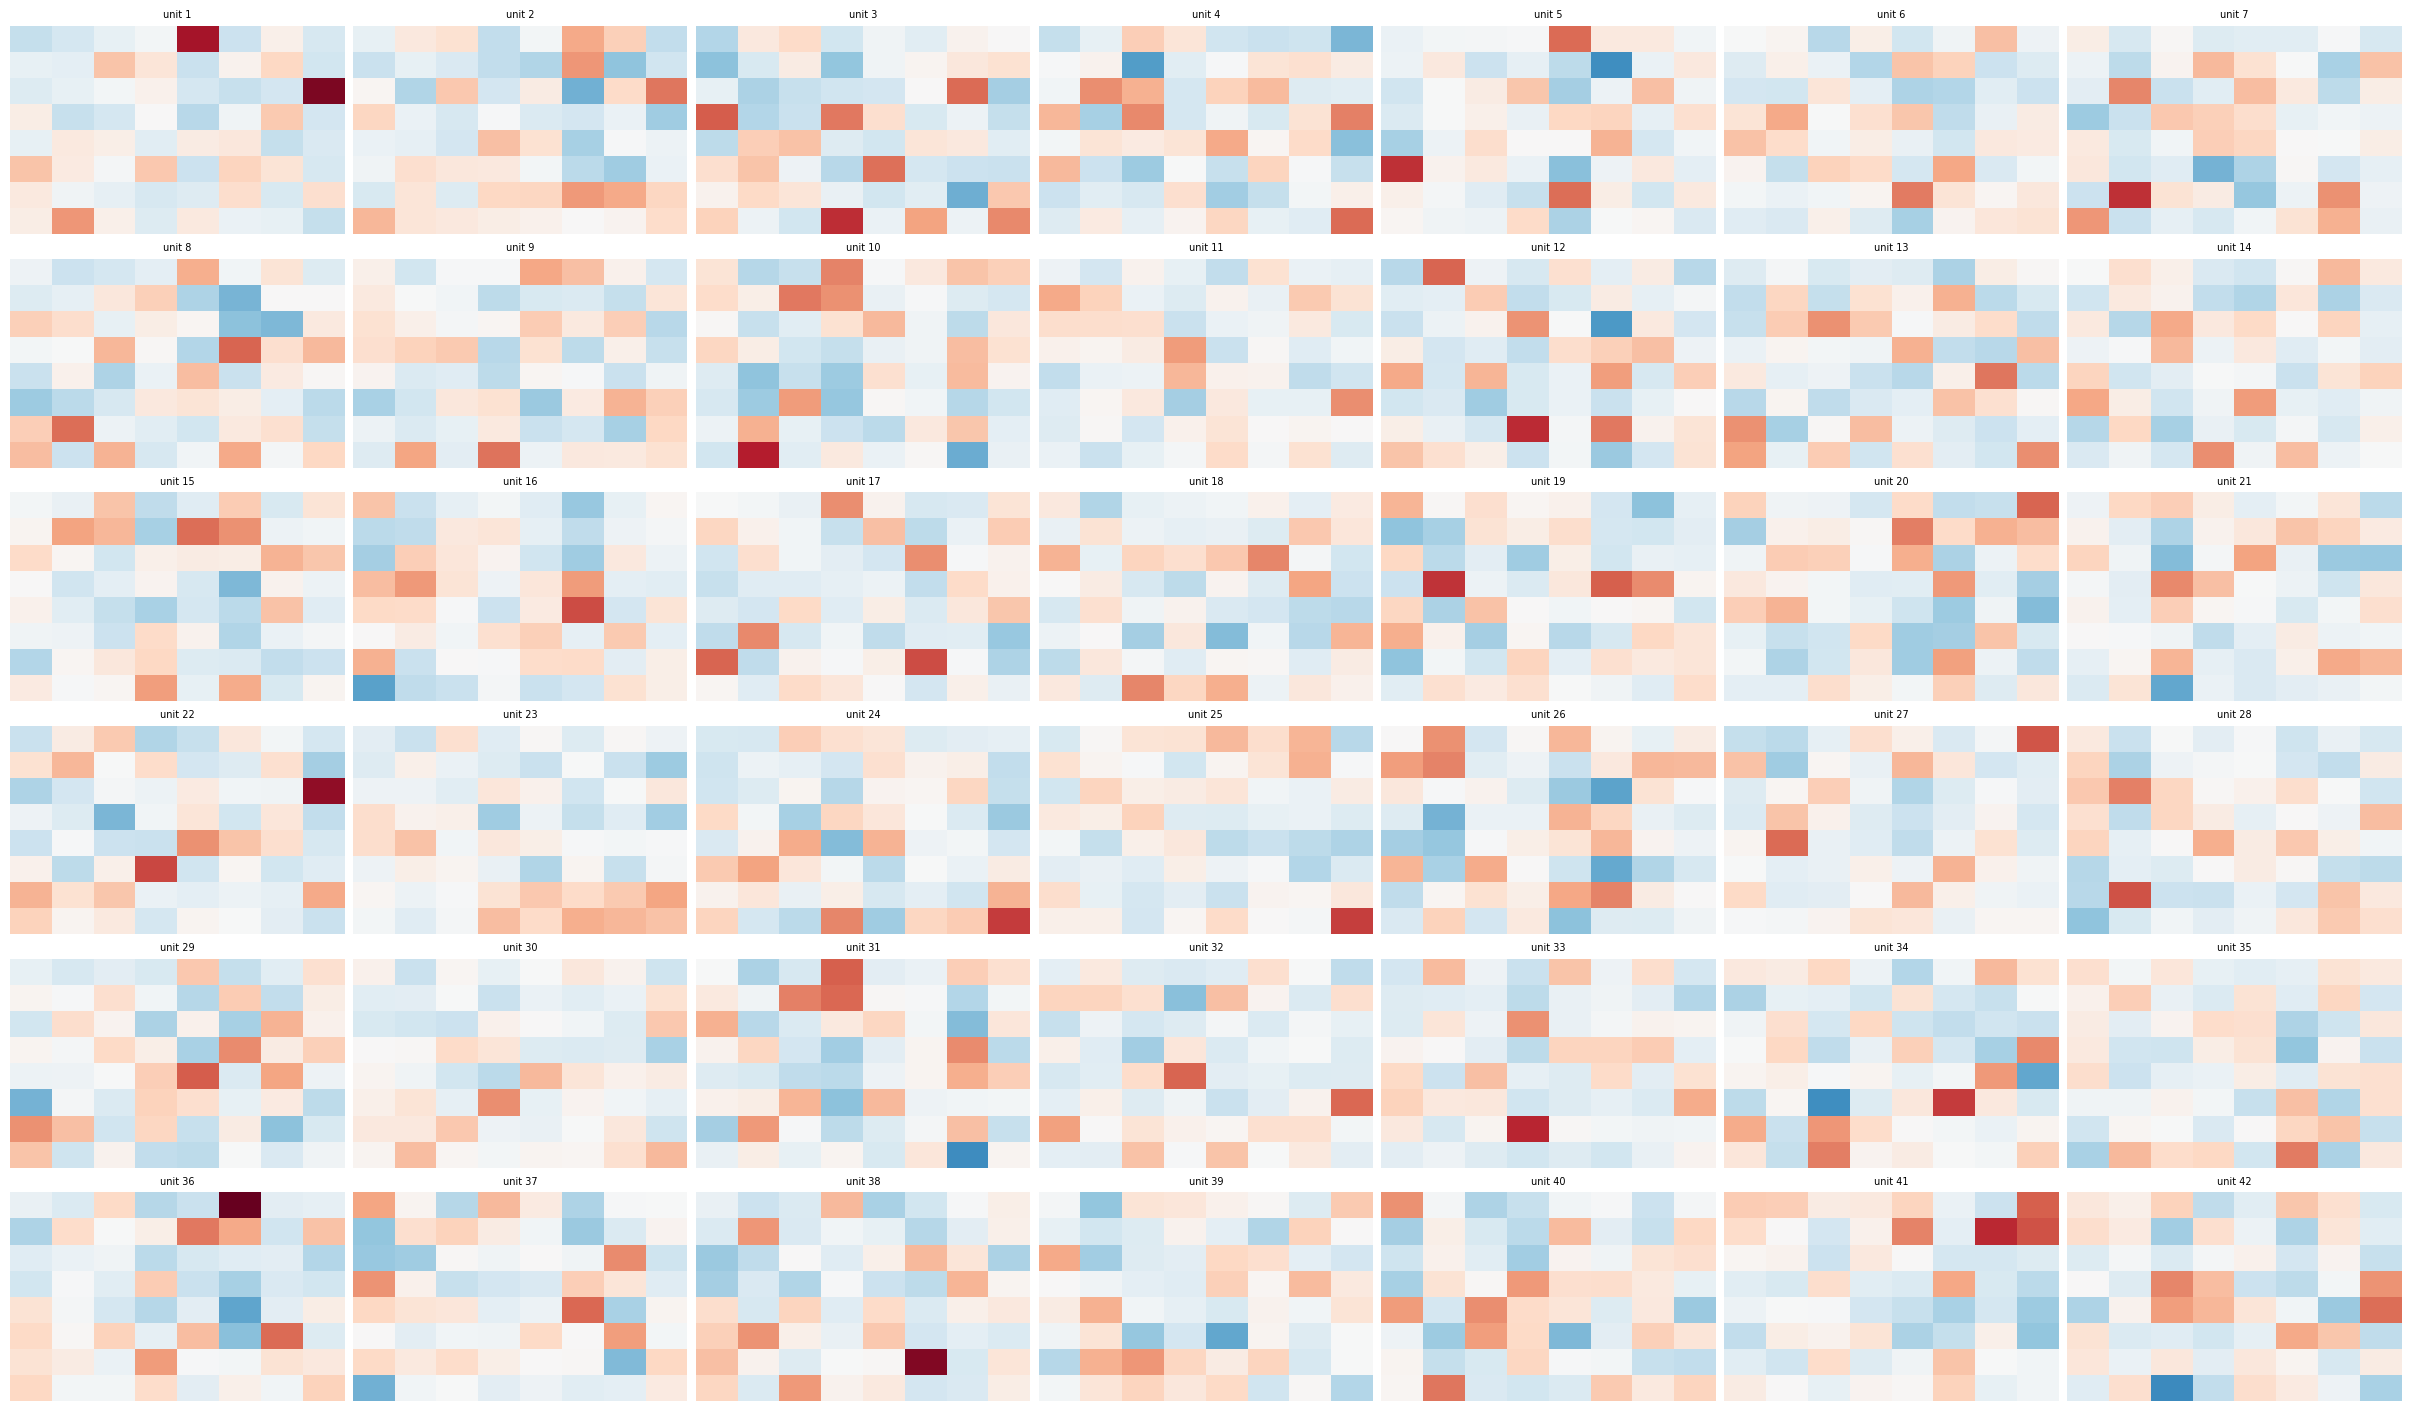

In [725]:
W_log = logmodel_weights.reshape(N_CLASSES, N_UNITS, N_BINS)

fig, axes = plt.subplots(
    6, 7,
    figsize=(24, 14),
    sharex=True, sharey=True,
    constrained_layout=True,
)
axes = axes.flatten()

vmax = np.abs(W_log).max()
for u in range(N_UNITS):
    sns.heatmap(
        W_log[:, u, :], ax=axes[u],
        cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
        cbar=False, xticklabels=False, yticklabels=False,
    )
    axes[u].set_title(f"unit {u+1}", fontsize=7)

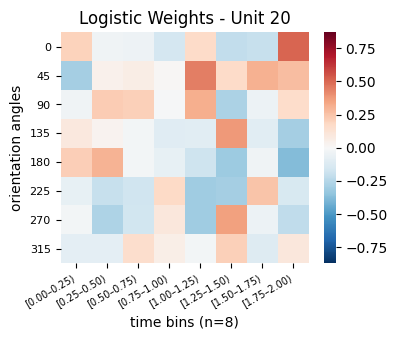

In [731]:
def plot_unit_weights(unit_num, figsize=(4, 3)):
    unit_index = unit_num - 1
    fig, ax = plt.subplots(figsize=figsize)
    
    vmax = np.abs(W_log).max()
    sns.heatmap(
        W_log[:, unit_index, :],
        cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
        cbar=True, xticklabels=False, yticklabels=False,
    )
    ax.set_title(f"Logistic Weights - Unit {unit_num}")
    
    ax.set_xlabel(f"time bins (n={N_BINS})")
    bin_labels = [f"[{i*BIN_WIDTH:.2f}–{(i+1)*BIN_WIDTH:.2f})" for i in range(N_BINS)]
    ax.set_xticks(np.arange(N_BINS) + 0.5)
    ax.set_xticklabels(bin_labels, rotation=30, ha="right", fontsize=7)
    
    ax.set_ylabel("orientation angles")
    orientations = [0, 45, 90, 135, 180, 225, 270, 315]
    ax.set_yticks(np.arange(len(orientations)) + 0.5)
    ax.set_yticklabels(orientations, fontsize=8)
    
    plt.show()

plot_unit_weights(20)

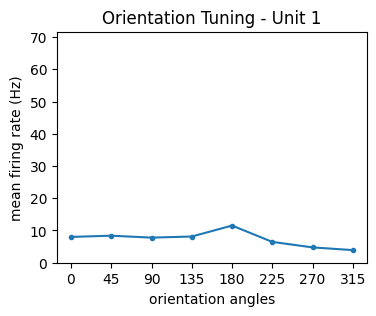

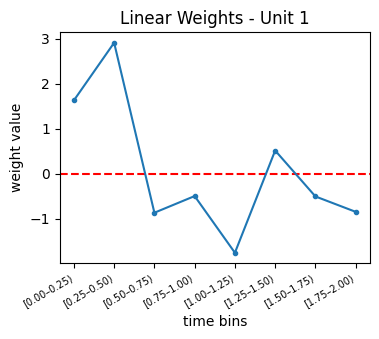

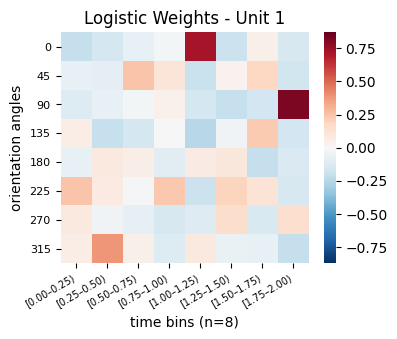

In [729]:
unit_of_interest = 1

plot_unit_tuning(unit_of_interest)
plot_lin_weights(unit_of_interest)
plot_unit_weights(unit_of_interest)

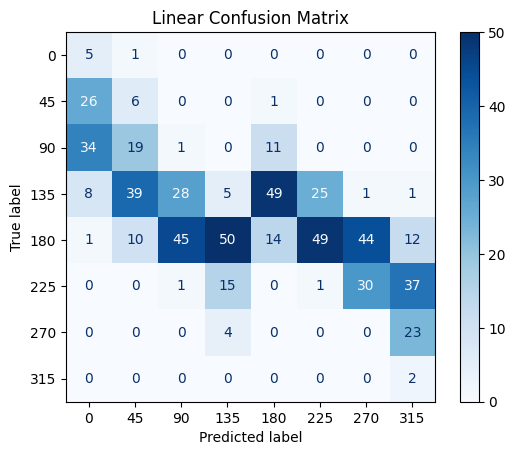

In [756]:
lin_pred = best_linreg.predict(X)
rounded_preds = np.around(lin_pred/45, decimals=0) * 45

j = ConfusionMatrixDisplay(confusion_matrix(rounded_preds, y), display_labels=orientations)
j.plot(cmap=plt.cm.Blues)
plt.title('Linear Confusion Matrix')
plt.show()

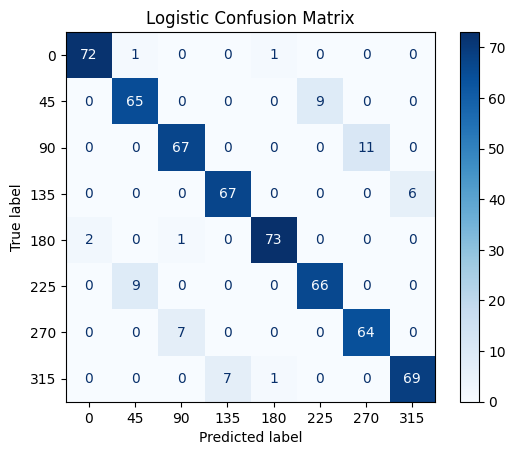

In [755]:
log_preds = best_logreg.predict(X)
j = ConfusionMatrixDisplay(confusion_matrix(log_preds, y), display_labels=orientations)
j.plot(cmap=plt.cm.Blues)
plt.title('Logistic Confusion Matrix')
plt.show()